In [1]:
import sys
sys.path.append("../src")

from preprocessing import handle_missing_values
from feature_engineering import create_features
from split_data import time_series_split
from train_models import train_baseline, train_random_forest, train_xgboost
from quantile_models import train_quantile_xgboost
from evaluation import evaluate_model, plot_comparison
from export_onnx import export_to_onnx, verify_onnx

import pandas as pd
import numpy as np
import json
import pathlib


In [2]:

# ─────────────────────────────────────────────────────────
# Cell 2: Nạp dữ liệu 1 trạm (bắt đầu đơn giản)
# ─────────────────────────────────────────────────────────
data_dir = pathlib.Path("../data/beijing_raw/PRSA_Data_20130301-20170228")
df = pd.read_csv(data_dir / "PRSA_Data_Dongsi_20130301-20170228.csv")

# Tạo datetime index
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]].astype(str).agg("-".join, axis=1),
    format="%Y-%m-%d-%H"
)
df = df.set_index("datetime").sort_index()
print(f"Dữ liệu gốc: {df.shape}")



Dữ liệu gốc: (35064, 18)


In [3]:
# ─────────────────────────────────────────────────────────
# Cell 3: Xử lý missing values
# ─────────────────────────────────────────────────────────
df_clean = handle_missing_values(df, target_col="PM2.5", max_gap_hours=6)


═══ XỬ LÝ MISSING VALUES ═══

Missing TRƯỚC khi xử lý:
PM2.5     750
PM10      553
SO2       663
NO2      1601
CO       3197
O3        664
TEMP       20
PRES       20
DEWP       20
RAIN       20
WSPM       14

Missing SAU khi nội suy (limit=6h):
PM2.5     324
PM10      230
SO2       254
NO2      1232
CO       2640
O3        234

Xóa 324 dòng vẫn còn NaN ở 'PM2.5'
Còn lại: 34,740 dòng


In [4]:
# ─────────────────────────────────────────────────────────
# Cell 4: Feature Engineering
# ─────────────────────────────────────────────────────────

# handle_missing_values() removes rows whose PM2.5 target remains missing.
# Restore those timestamps as NaN rows so shift(1) really means one elapsed hour,
# not merely the previous remaining row.
df_clean = df_clean.sort_index()

if not df_clean.index.is_unique:
    raise ValueError("Datetime index contains duplicate timestamps.")

df_clean = df_clean.asfreq("h")

time_gaps = df_clean.index.to_series().diff().dropna()
assert time_gaps.eq(pd.Timedelta(hours=1)).all(), (
    "Datetime index is not a continuous hourly grid."
)

df_features = create_features(df_clean, target_col="PM2.5")


═══ FEATURE ENGINEERING ═══

  ✓ Lag features: 6 cột (lags: [1, 2, 3, 6, 12, 24])
  ✓ Rolling features: 6 columns
  ✓ Time features: 5 cột (hour sin/cos, month sin/cos, day_of_week)
  ✓ Wind features: 2 cột (u, v decomposition)

  Xóa 4209 dòng NaN (do lag/rolling cần dữ liệu trước đó)
  Còn lại: 30,855 dòng
  Tổng số features: 29
  Danh sách features:
    ['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'PM2.5_lag_1h', 'PM2.5_lag_2h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'day_of_week', 'wind_u', 'wind_v']


In [5]:
# ─────────────────────────────────────────────────────────
# Cell 4: Feature Engineering
# ─────────────────────────────────────────────────────────

# handle_missing_values() removes rows whose PM2.5 target remains missing.
# Restore those timestamps as NaN rows so shift(1) really means one elapsed hour,
# not merely the previous remaining row.
df_clean = df_clean.sort_index()

if not df_clean.index.is_unique:
    raise ValueError("Datetime index contains duplicate timestamps.")

df_clean = df_clean.asfreq("h")

time_gaps = df_clean.index.to_series().diff().dropna()
assert time_gaps.eq(pd.Timedelta(hours=1)).all(), (
    "Datetime index is not a continuous hourly grid."
)

df_features = create_features(df_clean, target_col="PM2.5")


═══ FEATURE ENGINEERING ═══

  ✓ Lag features: 6 cột (lags: [1, 2, 3, 6, 12, 24])
  ✓ Rolling features: 6 columns
  ✓ Time features: 5 cột (hour sin/cos, month sin/cos, day_of_week)
  ✓ Wind features: 2 cột (u, v decomposition)

  Xóa 4209 dòng NaN (do lag/rolling cần dữ liệu trước đó)
  Còn lại: 30,855 dòng
  Tổng số features: 29
  Danh sách features:
    ['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'PM2.5_lag_1h', 'PM2.5_lag_2h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'day_of_week', 'wind_u', 'wind_v']


In [6]:


# Diagnostic: kiểm tra target leakage sau Feature Engineering
# Chạy ngay sau Cell 4.

# 1. Kiểm tra feature gây leakage trực tiếp đã được loại bỏ.
leak_feature = "PM2.5_change_24h"

if leak_feature not in df_features.columns:
    print(
        "PASS: PM2.5_change_24h không còn trong feature set; "
        "đã loại bỏ feature có thể mã hóa trực tiếp PM2.5 tại thời điểm t."
    )
else:
    reconstructed_target = (
        df_features["PM2.5_lag_24h"]
        + df_features[leak_feature]
    )
    max_identity_error = (
        reconstructed_target - df_features["PM2.5"]
    ).abs().max()

    print(
        "Max error for lag_24h + change_24h = PM2.5:",
        max_identity_error
    )
    if np.isclose(max_identity_error, 0.0, atol=1e-10):
        raise AssertionError(
            "Target leakage detected: lag_24h + change_24h "
            "reconstructs the current PM2.5 target."
        )
    print("PASS: no exact algebraic reconstruction of the target.")

# 2. Verify rolling means/std use only prior observations (shift(1)).
# Cell 4 has restored a continuous hourly index, so row shifts equal hours.
# Recalculate from df_clean and align to df_features' retained timestamps.
for window in (6, 12, 24):
    historical_pm25 = df_clean["PM2.5"].shift(1)

    expected_mean = (
        historical_pm25
        .rolling(window=window, min_periods=window)
        .mean()
        .reindex(df_features.index)
    )
    expected_std = (
        historical_pm25
        .rolling(window=window, min_periods=window)
        .std()
        .reindex(df_features.index)
    )

    actual_mean = df_features[f"PM2.5_roll_mean_{window}h"]
    actual_std = df_features[f"PM2.5_roll_std_{window}h"]

    mean_ok = np.allclose(
        actual_mean.to_numpy(),
        expected_mean.to_numpy(),
        rtol=1e-7,
        atol=1e-8,
        equal_nan=True
    )
    std_ok = np.allclose(
        actual_std.to_numpy(),
        expected_std.to_numpy(),
        rtol=1e-7,
        atol=1e-8,
        equal_nan=True
    )

    print(
        f"Rolling {window}h: "
        f"mean={'PASS' if mean_ok else 'FAIL'}, "
        f"std={'PASS' if std_ok else 'FAIL'}"
    )

    if not (mean_ok and std_ok):
        raise AssertionError(
            f"Rolling {window}h features do not match "
            "calculations using shift(1). Check src/feature_engineering.py."
        )

print("\\n✅ Leakage diagnostics passed.")


PASS: PM2.5_change_24h không còn trong feature set; đã loại bỏ feature có thể mã hóa trực tiếp PM2.5 tại thời điểm t.
Rolling 6h: mean=PASS, std=PASS
Rolling 12h: mean=PASS, std=PASS


Rolling 24h: mean=PASS, std=PASS
\n✅ Leakage diagnostics passed.


In [7]:

# ─────────────────────────────────────────────────────────
# Cell 5: Chia tập Train/Val/Test
# ─────────────────────────────────────────────────────────
X_train, X_val, X_test, y_train, y_val, y_test, scaler = time_series_split(
    df_features, target_col="PM2.5"
)


═══ CHIA TẬP DỮ LIỆU (Time Series Split) ═══

  Train:  21,598 dòng  (2013-03-02 00:00:00 → 2016-01-18 19:00:00)
  Val:     4,628 dòng  (2016-01-18 20:00:00 → 2016-08-10 17:00:00)
  Test:    4,629 dòng  (2016-08-10 18:00:00 → 2017-02-28 23:00:00)

  Features (29 cột): ['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'PM2.5_lag_1h', 'PM2.5_lag_2h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'day_of_week', 'wind_u', 'wind_v']
  StandardScaler: fit trên Train, transform cả 3 tập ✓


In [8]:

# ─────────────────────────────────────────────────────────
# Cell 6: Huấn luyện 3 mô hình
# ─────────────────────────────────────────────────────────
model_lr = train_baseline(X_train, y_train, X_val, y_val)
model_rf = train_random_forest(X_train, y_train, X_val, y_val)
model_xgb = train_xgboost(X_train, y_train, X_val, y_val)



🔹 MODEL 1: Linear Regression (Baseline)
  Train RMSE: 16.82 µg/m³
  Val   RMSE: 15.69 µg/m³
  Val   R²:   0.9470
  Thời gian:  0.04s

🔹 MODEL 2: Random Forest
  Train RMSE: 9.90 µg/m³
  Val   RMSE: 13.58 µg/m³
  Val   R²:   0.9603
  Thời gian:  7.00s
  Top-5 features: [('PM2.5_lag_1h', '0.933'), ('PM10', '0.048'), ('CO', '0.004'), ('PM2.5_lag_2h', '0.001'), ('SO2', '0.001')]

🔹 MODEL 3: XGBoost (Mô hình chính)
  Train RMSE: 8.66 µg/m³
  Val   RMSE: 15.27 µg/m³
  Val   R²:   0.9498
  Best iter:  247
  Thời gian:  1.39s
  Top-5 features: [('PM2.5_lag_1h', '0.531'), ('PM2.5_roll_mean_6h', '0.192'), ('PM2.5_lag_2h', '0.126'), ('PM10', '0.075'), ('CO', '0.024')]



📊 Đánh giá: LinearRegression
  RMSE:     18.35 µg/m³
  MAE:      10.02 µg/m³
  R²:       0.9696
  Macro-F1: 0.8100
  📄 Biểu đồ lưu tại: ../results/LinearRegression_test.png


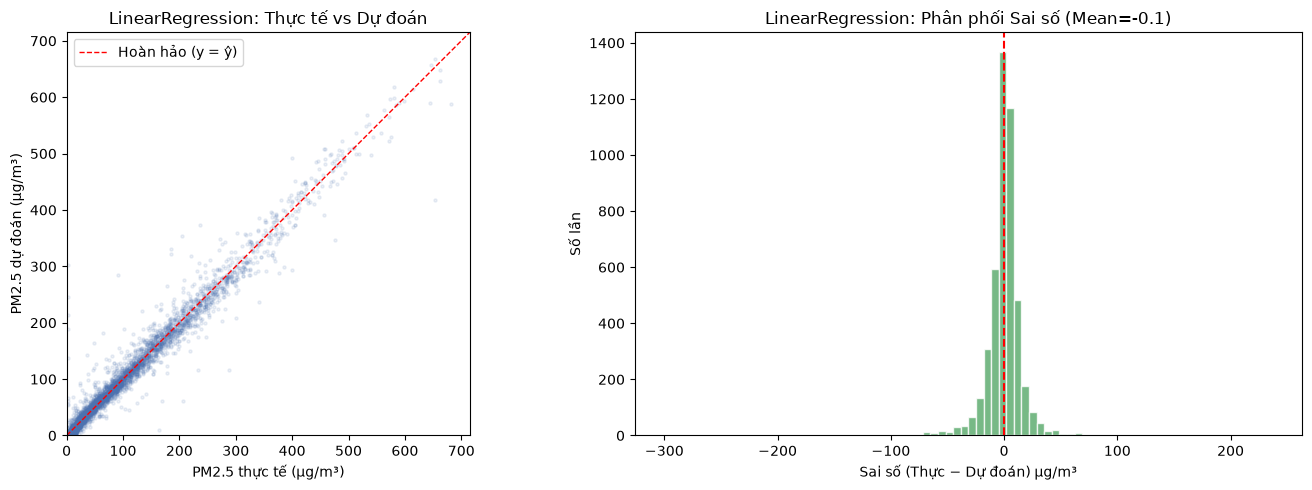


📊 Đánh giá: RandomForest
  RMSE:     16.65 µg/m³
  MAE:      8.12 µg/m³
  R²:       0.9750
  Macro-F1: 0.8445
  📄 Biểu đồ lưu tại: ../results/RandomForest_test.png


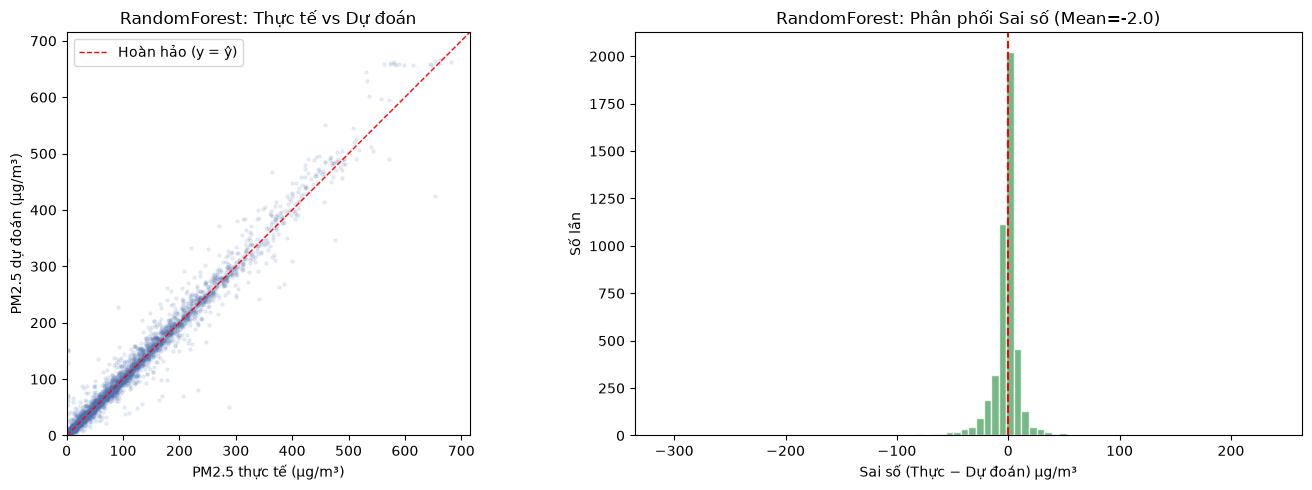


📊 Đánh giá: XGBoost
  RMSE:     17.63 µg/m³
  MAE:      8.63 µg/m³
  R²:       0.9719
  Macro-F1: 0.8420
  📄 Biểu đồ lưu tại: ../results/XGBoost_test.png


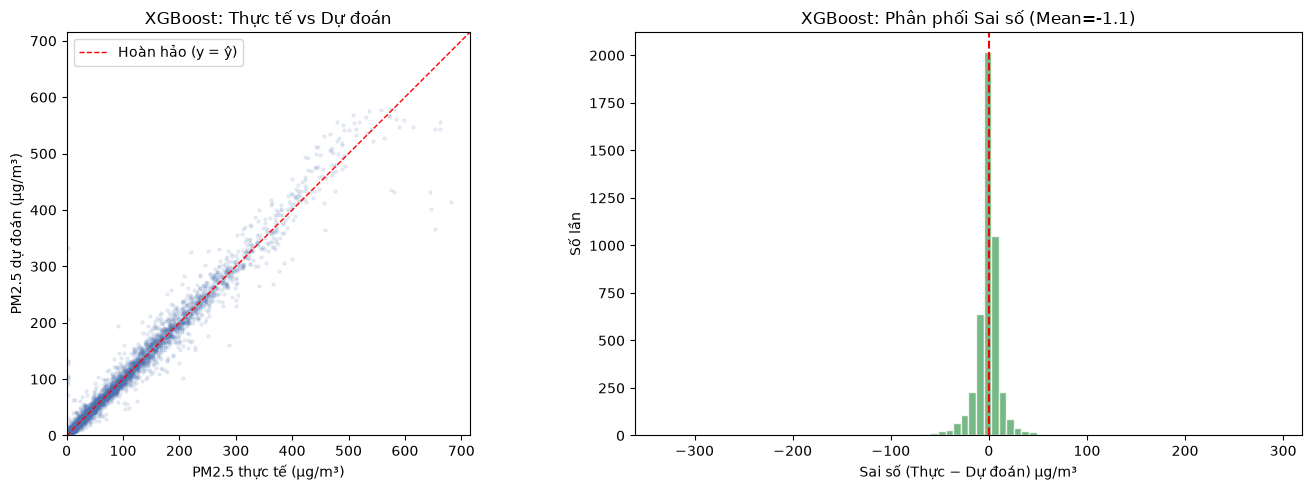


📊 BẢNG SO SÁNH CUỐI CÙNG (trên tập Test)
           Model  RMSE   MAE     R²  Macro-F1
LinearRegression 18.35 10.02 0.9696    0.8100
    RandomForest 16.65  8.12 0.9750    0.8445
         XGBoost 17.63  8.63 0.9719    0.8420


In [9]:

# ─────────────────────────────────────────────────────────
# Cell 7: Đánh giá trên tập TEST (chỉ 1 lần duy nhất!)
# ─────────────────────────────────────────────────────────
results = []
for name, model in [("LinearRegression", model_lr),
                     ("RandomForest", model_rf),
                     ("XGBoost", model_xgb)]:
    y_pred = model.predict(X_test)
    r = evaluate_model(y_test.values, y_pred, model_name=name)
    results.append(r)
    plot_comparison(y_test.values, y_pred, name,
                    save_path=f"../results/{name}_test.png")

# Bảng so sánh
results_df = pd.DataFrame(results)
print("\n" + "="*60)
print("📊 BẢNG SO SÁNH CUỐI CÙNG (trên tập Test)")
print("="*60)
print(results_df.to_string(index=False))
results_df.to_csv("../results/model_comparison.csv", index=False)


In [10]:

# ─────────────────────────────────────────────────────────
# Cell 8: Quantile Regression (khoảng bất định)
# ─────────────────────────────────────────────────────────
print("\n🔹 Huấn luyện Quantile Models...")
model_q05 = train_quantile_xgboost(X_train, y_train, X_val, y_val, alpha=0.05)
model_q95 = train_quantile_xgboost(X_train, y_train, X_val, y_val, alpha=0.95)



🔹 Huấn luyện Quantile Models...
  Quantile α=0.05: best_iteration=499
  Quantile α=0.95: best_iteration=499


In [11]:
# ─────────────────────────────────────────────────────────
# Diagnostic: đánh giá prediction interval Q05–Q95 trên TEST
# ─────────────────────────────────────────────────────────
y_true = y_test.to_numpy()
q05_pred = model_q05.predict(X_test)
q95_pred = model_q95.predict(X_test)

def mean_pinball_loss(y_true, y_pred, alpha):
    residual = y_true - y_pred
    return np.mean(
        np.maximum(alpha * residual, (alpha - 1) * residual)
    )

coverage = np.mean((y_true >= q05_pred) & (y_true <= q95_pred))
mean_width = np.mean(q95_pred - q05_pred)
crossing_count = int(np.sum(q05_pred > q95_pred))

print("═══ QUANTILE MODEL EVALUATION (TEST) ═══")
print(f"Q05 pinball loss: {mean_pinball_loss(y_true, q05_pred, 0.05):.4f}")
print(f"Q95 pinball loss: {mean_pinball_loss(y_true, q95_pred, 0.95):.4f}")
print(f"Empirical coverage: {coverage:.2%} (target: 90%)")
print(f"Mean interval width: {mean_width:.3f} µg/m³")
print(f"Quantile crossings (Q05 > Q95): {crossing_count:,} / {len(y_true):,}")

if crossing_count > 0:
    print("WARNING: Some lower-quantile predictions exceed upper-quantile predictions.")


═══ QUANTILE MODEL EVALUATION (TEST) ═══
Q05 pinball loss: 1.3501
Q95 pinball loss: 1.7188
Empirical coverage: 92.40% (target: 90%)
Mean interval width: 42.046 µg/m³
Quantile crossings (Q05 > Q95): 0 / 4,629


In [12]:
booster = model_xgb.get_booster()

print(booster.feature_names)

['PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'PM2.5_lag_1h', 'PM2.5_lag_2h', 'PM2.5_lag_3h', 'PM2.5_lag_6h', 'PM2.5_lag_12h', 'PM2.5_lag_24h', 'PM2.5_roll_mean_6h', 'PM2.5_roll_std_6h', 'PM2.5_roll_mean_12h', 'PM2.5_roll_std_12h', 'PM2.5_roll_mean_24h', 'PM2.5_roll_std_24h', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'day_of_week', 'wind_u', 'wind_v']


In [13]:
import importlib
import export_onnx

importlib.reload(export_onnx)

export_to_onnx = export_onnx.export_to_onnx
verify_onnx = export_onnx.verify_onnx

In [14]:
import joblib
import json
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the scaler fitted on X_train.
joblib.dump(scaler, model_dir / "airwise_scaler.pkl")

# Save the exact feature order expected by the trained models.
with open(model_dir / "airwise_feature_columns.json", "w", encoding="utf-8") as f:
    json.dump(list(X_train.columns), f, ensure_ascii=False, indent=2)

print("Saved scaler and feature-order metadata.")


Saved scaler and feature-order metadata.


In [15]:
# ─────────────────────────────────────────────────────────
# Cell 9: Xuất ONNX và kiểm chứng cả 3 mô hình
# ─────────────────────────────────────────────────────────
n_features = X_train.shape[1]
X_sample = X_test.iloc[:100]

onnx_models = [
    ("Point", model_xgb, "../models/xgboost_pm25_point.onnx"),
    ("Q05", model_q05, "../models/xgboost_pm25_q05.onnx"),
    ("Q95", model_q95, "../models/xgboost_pm25_q95.onnx"),
]

# Chạy lại Cell 9 trong notebook
for model_name, fitted_model, onnx_path in onnx_models:
    print(f"\nExporting {model_name} model...")
    export_to_onnx(fitted_model, n_features, onnx_path)

    print(f"Verifying {model_name} model...")
    verify_onnx(fitted_model, onnx_path, X_sample.to_numpy())



Exporting Point model...
  ONNX saved: ../models/xgboost_pm25_point.onnx (0.82 MB)
Verifying Point model...

  🔍 Kiểm chứng ONNX vs Original:
     Max abs diff:  5.34e-05
     Mean abs diff: 1.30e-05
     ✅ PASS — Sai lệch chấp nhận được (nằm trong dung sai float32)

Exporting Q05 model...
  ONNX saved: ../models/xgboost_pm25_q05.onnx (1.78 MB)
Verifying Q05 model...

  🔍 Kiểm chứng ONNX vs Original:
     Max abs diff:  7.63e-05
     Mean abs diff: 1.44e-05
     ✅ PASS — Sai lệch chấp nhận được (nằm trong dung sai float32)

Exporting Q95 model...
  ONNX saved: ../models/xgboost_pm25_q95.onnx (1.74 MB)
Verifying Q95 model...

  🔍 Kiểm chứng ONNX vs Original:
     Max abs diff:  2.90e-04
     Mean abs diff: 8.48e-05
     ✅ PASS — Sai lệch chấp nhận được (nằm trong dung sai float32)
